# 02 · EGCC: радиус C40, сфера и WGS84

**Исследовательский вопрос:** Как меняется радиальное отклонение при выборе метрики и насколько велик возможный вклад координатной сетки?

**Входные материалы:** аналитический Parquet Европы и проверенные исторические координаты EGCC

Расчеты ниже выполняются в ячейках. Все исходные строки сохраняются. Округление таблиц используется только для чтения результатов.

In [1]:
# Подключаем библиотеки и находим корень проекта
from pathlib import Path
import hashlib
import json
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython import get_ipython
from IPython.display import display, Markdown
root = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p/'research/c40_geometry').is_dir())
study = root/'research/c40_geometry'
# Подключаем проверенные геодезические функции без запуска скриптов
sys.path.insert(0, str(root/'europe/scripts'))
from audit_c40_radial_cases import ellipsoid_distance, validate_distance
from investigate_c40_geometry import distance
if get_ipython() is not None:
    get_ipython().run_line_magic('matplotlib', 'inline')
plt.rcParams.update({'figure.dpi':120, 'font.size':11,
                     'axes.spines.top':False, 'axes.spines.right':False})
# Таблицы округляем только при отображении, расчетные значения сохраняем
pd.set_option('display.max_columns', 14)


## 1. Проверяем вход и читаем EGCC

Контрольная сумма связывает расчет с конкретной версией данных. Фильтр выбирает аэропорт, не удаляя строки исходного файла.

In [2]:
import pyarrow.parquet as pq
# Сверяем версию исходного аналитического файла потоковым чтением
source = root/'europe/data/analytical/06_05_cases_excluded.parquet'
audit = json.loads((study/'reports/egcc_geometry_audit.json').read_text(encoding='utf8'))
sha = hashlib.sha256()
with source.open('rb') as stream:
    for chunk in iter(lambda:stream.read(8*1024*1024), b''):
        sha.update(chunk)
assert sha.hexdigest() == audit['input_sha256']
display(validate_distance())
# Читаем только поля, необходимые для геометрического расчета
fields = ['flight_id','GoA','C40_CROSS_LAT','C40_CROSS_LON','C40_BEARING']
frame = pq.read_table(source, columns=fields, filters=[('airport','=','EGCC')]).to_pandas()
display(frame.head())
display(frame.GoA.value_counts().rename('Число записей'))

{'ngs_reference_m': 191872.119,
 'ngs_computed_m': 191872.11902784643,
 'geographiclib_reference_m': 5551759.400318678,
 'geographiclib_computed_m': 5551759.400334103,
 'tolerance_m': 0.002}

,flight_id,GoA,C40_CROSS_LAT,C40_CROSS_LON,C40_BEARING
0,UAE1KM_76155,False,52.984167,-1.348611,123.283140
1,EIN20M_65237,False,53.536667,-3.353056,286.322367
2,ETH728_199,False,52.950000,-1.390278,126.925429
3,TCX2607_8677,False,52.954167,-1.383333,126.422949
4,SWR33K_50854,False,52.880556,-1.493056,134.931455


GoA
False    87129
True       306
Name: Число записей, dtype: int64

## 2. Считаем расстояния и отклонения

40 морских миль соответствуют 74,08 км. Разность расстояния и этого радиуса – диагностическая величина. Используемая авторами модель расстояния пока не установлена.

In [3]:
# Проверяем координаты исторического ARP перед расчетом
arp_lat, arp_lon = audit['arp_lat'], audit['arp_lon']
official = pd.read_csv(study/'reports/historical_arp_sources.csv')
official = official[(official.airport == 'EGCC') & (official.designation == 'explicit_ARP_AD2_2')]
assert np.allclose(official.published_lat, arp_lat, atol=1e-12, rtol=0)
assert np.allclose(official.published_lon, arp_lon, atol=1e-12, rtol=0)
lat, lon = frame.C40_CROSS_LAT.to_numpy(), frame.C40_CROSS_LON.to_numpy()
# Сравниваем одну и ту же точку на сфере и эллипсоиде
frame['sphere_km'] = distance(arp_lat, arp_lon, lat, lon)
frame['wgs84_km'] = ellipsoid_distance(arp_lat, arp_lon, lat, lon)
frame['deviation_m'] = (frame.wgs84_km-74.08)*1000
frame['sphere_deviation_m'] = (frame.sphere_km-74.08)*1000
frame['model_difference_m'] = (frame.wgs84_km-frame.sphere_km)*1000
display(frame.groupby('GoA')[['deviation_m','sphere_deviation_m','model_difference_m']].agg(['median','min','max']).round(2))

deviation_m                   sphere_deviation_m                    \
           median      min      max             median      min      max   
GoA                                                                        
False      240.68 -1065.58  1548.36              76.37 -1256.62  1312.63   
True       212.11  -101.43   909.42              49.22  -292.38   667.60   

      model_difference_m                 
                  median    min     max  
GoA                                      
False             163.49  60.98  244.76  
True              162.75  65.93  244.29

## 3. Оцениваем вклад координатной сетки

Проверяем два условных сценария: ±0,5 и ±1 угловая секунда по каждой координате. Алгоритм округления неизвестен. Расстояния до углов локальной ячейки дают оценку смещения для этих сценариев.

In [4]:
# Рассчитываем расстояние до четырех углов для каждого сценария
for name, width in [('nearest',.5), ('one_second',1.)]:
    corners = [1000*ellipsoid_distance(lat,lon,lat+dy*width/3600,lon+dx*width/3600)
               for dy in [-1,1] for dx in [-1,1]]
    frame[f'grid_{name}_bound_m'] = np.max(corners, axis=0)
display(frame[['grid_nearest_bound_m','grid_one_second_bound_m']].describe().round(2))
# Показываем превышения отдельно для обеих метрик без исключения записей
diagnostics = frame.groupby('GoA').agg(rows=('flight_id','size'))
for name in ['deviation_m','sphere_deviation_m']:
    diagnostics[name+'_gt_bound'] = frame.groupby('GoA')[name].apply(
        lambda s:int((s.abs() > frame.loc[s.index,'grid_one_second_bound_m']).sum()))
display(diagnostics)

,grid_nearest_bound_m,grid_one_second_bound_m
count,87435.00,87435.00
mean,18.03,36.07
std,0.04,0.08
min,17.94,35.88
25%,17.99,35.99
50%,18.06,36.12
75%,18.06,36.13
max,18.09,36.17


,rows,deviation_m_gt_bound,sphere_deviation_m_gt_bound
GoA,,,
False,87129,82111,71869
True,306,284,232


## 4. Сопоставляем распределения и азимут

GoA показан как описательный разрез. На рисунке распределения виден только диапазон от −1200 до 1700 м; экстремумы выше приведены в таблице. Различие метрик зависит от направления к точке.

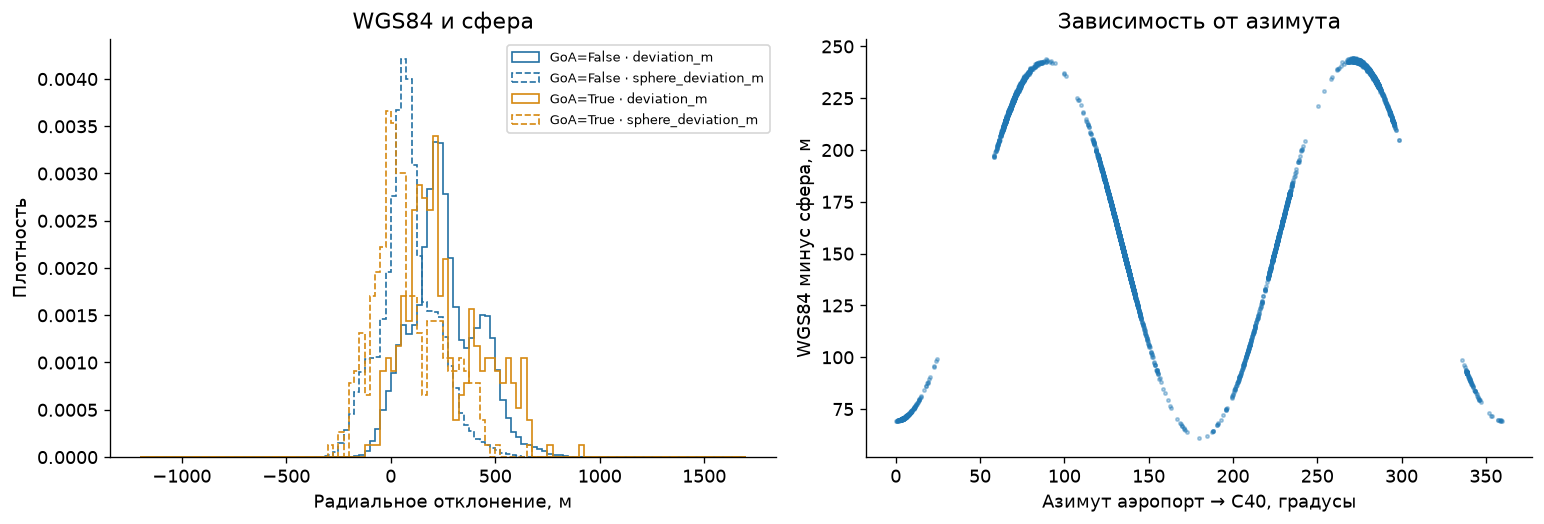

In [5]:
fig, axes = plt.subplots(1,2,figsize=(13,4.5))
# Используем одинаковые границы столбцов для обеих групп и метрик
for label, color in [(False,'#2471A3'),(True,'#D68910')]:
    group = frame[frame.GoA.eq(label)]
    for metric, style in [('deviation_m','-'),('sphere_deviation_m','--')]:
        axes[0].hist(group[metric], bins=np.arange(-1200,1701,25), density=True,
                     histtype='step', color=color, linestyle=style, label=f'GoA={label} · {metric}')
axes[0].set(xlabel='Радиальное отклонение, м', ylabel='Плотность', title='WGS84 и сфера')
axes[0].legend(fontsize=8)
# Для читаемости графика берем регулярную выборку только при отображении
sample = frame.iloc[::max(1,len(frame)//6000)]
axes[1].scatter(sample.C40_BEARING,sample.model_difference_m,s=4,alpha=.35)
axes[1].set(xlabel='Азимут аэропорт → C40, градусы',ylabel='WGS84 минус сфера, м',title='Зависимость от азимута')
plt.tight_layout()
plt.show()
# Сверяем пересчитанные числа с сохраненным аудитом
assert len(frame) == audit['rows'] and int(frame.GoA.sum()) == audit['goa']
assert np.isclose(frame.grid_one_second_bound_m.max(),audit['max_one_second_grid_bound_m'])

## Что установлено и что остается открытым

Метрика влияет на величину отклонения и состав диагностических случаев. Превышение выбранной границы сетки не устанавливает ошибку записи: определение пересечения и исходные траектории еще не проверены. Азимут от ARP не является магнитным курсом захода.

## Методические подробности и происхождение источников

# EGCC – независимая геометрическая проверка

ARP подтвержден историческими AD 2.2. Данные читаются из Европы, результаты сохраняются в research. Все записи сохраняются.

---

## Граница влияния сетки

Координаты лежат на сетке с шагом $h=1/3600$ градуса. Само наблюдение сетки не устанавливает алгоритм округления.

Для округления к ближайшему узлу предполагаем $|\delta\varphi|,|\delta\lambda|\le h/2$; для второго сценария допускаем до $h$ по каждой координате. Второй сценарий также требует предположения о максимальной ошибке: он не охватывает произвольную ошибку исходных координат.

В первом приближении смещение точки:
$$\epsilon\approx\sqrt{(M\delta\varphi)^2+(N\cos\varphi\,\delta\lambda)^2},$$
где приращения в радианах, $M=a(1-e^2)/(1-e^2\sin^2\varphi)^{3/2}$, $N=a/\sqrt{1-e^2\sin^2\varphi}$ – радиусы кривизны WGS84.

В расчетах используем геодезические расстояния до четырех углов ячейки; это оценка максимального смещения для указанных локальных ячеек. По неравенству треугольника при фиксированном ARP:
$$|d(A,P)-d(A,\widehat P)|\le d(P,\widehat P)\le\epsilon.$$
Если центр тоже имеет ошибку $\epsilon_A$, общая граница становится $\epsilon+\epsilon_A$. Здесь сравниваем с опубликованным ARP; точность его физического определения не установлена.

Отклонение от 74.08 км превышающее эту границу нельзя объяснить только выбранным сценарием квантования. Оно не становится автоматически ошибкой записи: определение пересечения, частота наблюдений и исходные траектории еще не проверены.


---

Воспроизведение из корня: `.\.venv\Scripts\python.exe -u -X utf8 research/c40_geometry/scripts/analyze_egcc_geometry.py`. Различия между GoA показаны описательно; причинный эффект и статистическая значимость не оценивались.